# 01 — Exploratory data analysis: Online Retail II

**Source:** [UCI Machine Learning Repository #502](https://archive.ics.uci.edu/dataset/502/online+retail+ii)
— every transaction of a UK-based online giftware wholesaler between 1 Dec 2009 and 9 Dec 2011.
Many customers are themselves small retailers.

**Goal of this notebook:** understand the raw data well enough to make (and justify) the cleaning
rules used in the ETL, then get a first read on the business: how revenue moves through the year,
who the customers are and how concentrated value is.

The data is read straight from the DuckDB warehouse built by `retail build`.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns

from retail import config

con = duckdb.connect(str(config.DB_PATH), read_only=True)
q = lambda sql: con.execute(sql).df()  # noqa: E731

COBALT, AMBER, TEAL, GREY = "#5A6CF0", "#E39B2D", "#2BB39E", "#8A93A3"
sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})
gbp = mtick.FuncFormatter(lambda x, _: f"£{x/1e3:,.0f}k" if abs(x) >= 1e3 else f"£{x:,.0f}")


def save(fig, name):
    fig.savefig(config.FIGURES / f"{name}.png", bbox_inches="tight", dpi=150)

## 1. First look at the raw (bronze) data
Eight source columns, two spreadsheet tabs, just over a million rows.

In [2]:
raw = q(f"select * from '{config.BRONZE.as_posix()}'")
print(f"{len(raw):,} rows x {raw.shape[1]} columns")
raw.drop(columns=["_ingested_at"]).head()

1,067,371 rows x 11 columns


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,_source_sheet,_source_row
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,Year 2009-2010,2
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010,3
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010,4
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,Year 2009-2010,5
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,Year 2009-2010,6


In [3]:
profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(2),
    "distinct": raw.nunique(),
}).drop(index=["_ingested_at", "_source_row"])
profile

,dtype,missing,missing_%,distinct
Invoice,str,0,0.00,53628
StockCode,str,0,0.00,5305
Description,str,4382,0.41,5698
Quantity,int64,0,0.00,1057
InvoiceDate,datetime64[us],0,0.00,47635
Price,float64,0,0.00,2807
Customer ID,float64,243007,22.77,5942
Country,str,0,0.00,43
_source_sheet,str,0,0.00,2


**What stands out**

* **22.8 % of lines have no `Customer ID`.** These are real sales (guest checkouts) — they belong in
  revenue figures but can't be used for customer-level modelling.
* `Invoice` is text: a leading `C` marks a **cancellation** (credit note), `A` marks a bad-debt adjustment.
* `Quantity` ranges from −80,995 to +80,995: one huge order that was cancelled the same day.

In [4]:
num = raw[["Quantity", "Price"]].describe(percentiles=[.01, .05, .5, .95, .99]).T
num

,count,mean,std,min,1%,5%,50%,95%,99%,max
Quantity,1067371.0,9.938898,172.705794,-80995.00,-3.00,1.00,3.0,30.00,100.0,80995.0
Price,1067371.0,4.649388,123.553059,-53594.36,0.21,0.42,2.1,9.95,18.0,38970.0


## 2. Data quality issues found, and the rule used for each

Each finding below became a rule in `src/retail/transform.py`. Rows are **tagged, not deleted**,
so the funnel from raw to analysed data stays auditable.

In [5]:
issues = q("""
select 'exact duplicate lines' issue, count(*) - count(distinct (Invoice, StockCode, Description,
       Quantity, InvoiceDate, Price, "Customer ID", Country)) n from b
union all select 'cancellation lines (invoice starts with C)', count(*) from b where Invoice like 'C%'
union all select 'zero or negative unit price', count(*) from b where Price <= 0
union all select 'negative qty on a non-cancelled invoice', count(*) from b where Quantity < 0 and Invoice not like 'C%'
union all select 'missing description', count(*) from b where Description is null
union all select 'missing customer id', count(*) from b where "Customer ID" is null
union all select 'non-product stock codes (postage, fees, manual)', count(*) from b
          where StockCode in ('POST','DOT','M','C2','D','S','B','BANK CHARGES','AMAZONFEE','CRUK','PADS')
""".replace(" from b", f" from '{config.BRONZE.as_posix()}'"))
issues

,issue,n
0,exact duplicate lines,34335
1,cancellation lines (invoice starts with C),19494
2,zero or negative unit price,6207
3,negative qty on a non-cancelled invoice,3457
4,missing description,4382
5,missing customer id,243007
6,"non-product stock codes (postage, fees, manual)",5738


In [6]:
# Stock codes carry several spellings of the same product over two years.
q(f"""select StockCode, count(distinct Description) spellings, list(distinct Description)[:4] examples
from '{config.BRONZE.as_posix()}' group by 1 order by 2 desc limit 5""")

,StockCode,spellings,examples
0,20713,9,"[wrongly marked. 23343 in box, Marked as 23343..."
1,22423,7,"[None, broken, uneven bottom, wonky bottom/bro..."
2,23084,7,"[None, temp adjustment, add stock to allocate ..."
3,21181,7,"[check, dotcom, PLEASE ONE PERSON METAL SIGN,..."
4,22734,7,"[SET OF 6 RIBBONS VINTAGE CHRISTMAS, amazon sa..."


### The cleaning funnel
The order of the rules matters (a duplicated cancellation counts once, as a duplicate).

In [7]:
funnel = q("""select row_status, count(*) n_rows, round(sum(line_revenue), 0) revenue
              from silver_transactions group by 1 order by n_rows desc""")
funnel["share"] = (funnel["n_rows"] / funnel["n_rows"].sum()).map("{:.2%}".format)
funnel

,row_status,n_rows,revenue,share
0,valid_sale,1003214,19642692.0,93.99%
1,duplicate,34335,431717.0,3.22%
2,cancellation,17914,-716426.0,1.68%
3,zero_or_negative_price,5929,0.0,0.56%
4,non_product,5886,69112.0,0.55%
5,test_or_adjustment,93,-139844.0,0.01%


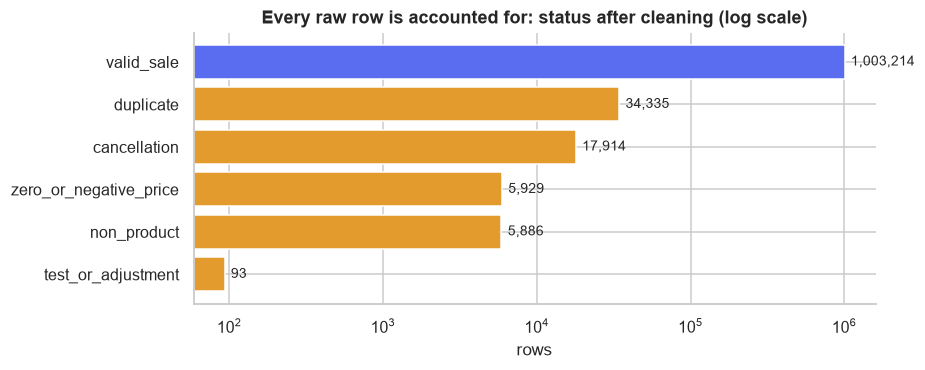

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.2))
f = funnel.sort_values("n_rows")
colors = [COBALT if s == "valid_sale" else AMBER for s in f["row_status"]]
ax.barh(f["row_status"], f["n_rows"], color=colors)
ax.set_xscale("log")
ax.set_title("Every raw row is accounted for: status after cleaning (log scale)")
ax.set_xlabel("rows")
for y, v in enumerate(f["n_rows"]):
    ax.text(v * 1.1, y, f"{v:,}", va="center", fontsize=9)
save(fig, "eda_cleaning_funnel")

## 3. Revenue over time
Weekly gross revenue (outlier orders excluded). Two complete peak seasons are visible.

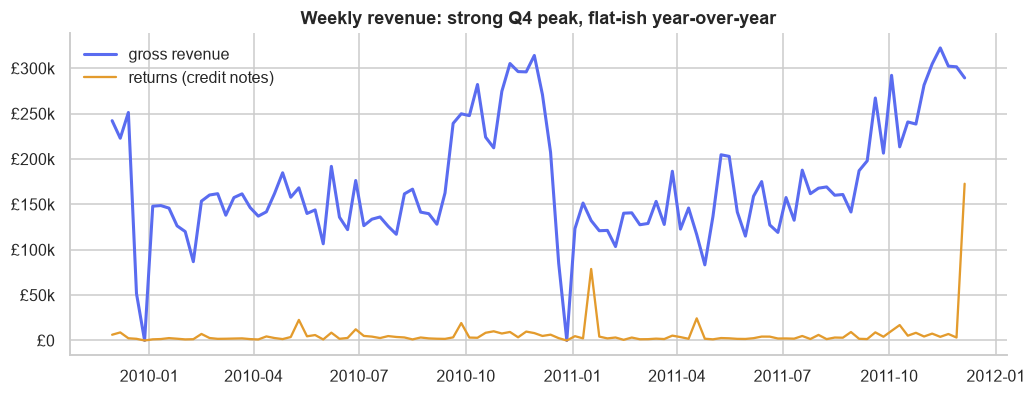

In [9]:
daily = q("select * from mart_daily_kpis order by date_key")
daily["date_key"] = pd.to_datetime(daily["date_key"])
weekly = daily.set_index("date_key")[["gross_revenue", "returns_value", "orders"]].resample("W-MON", label="left", closed="left").sum()

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(weekly.index, weekly["gross_revenue"], color=COBALT, lw=2, label="gross revenue")
ax.plot(weekly.index, -weekly["returns_value"], color=AMBER, lw=1.5, label="returns (credit notes)")
ax.yaxis.set_major_formatter(gbp)
ax.set_title("Weekly revenue: strong Q4 peak, flat-ish year-over-year")
ax.legend(frameon=False)
save(fig, "eda_weekly_revenue")

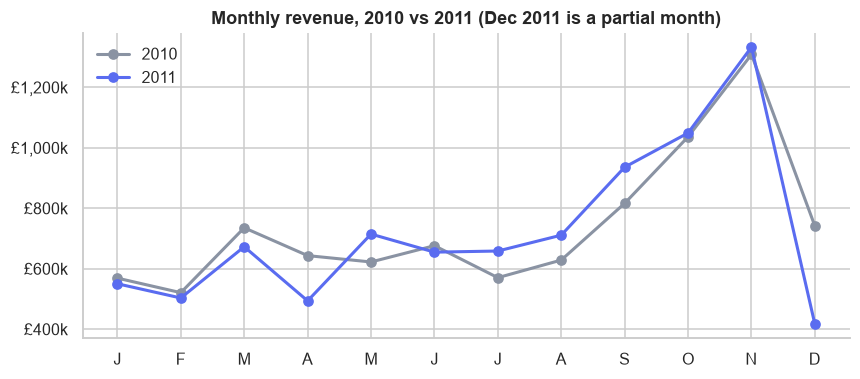

In [10]:
monthly = q("""select year, month, sum(gross_revenue) revenue from mart_daily_kpis
               group by 1, 2 order by 1, 2""")
pivot = monthly.pivot(index="month", columns="year", values="revenue")
fig, ax = plt.subplots(figsize=(9, 3.6))
for yr, c in zip([2010, 2011], [GREY, COBALT], strict=True):
    ax.plot(pivot.index, pivot[yr], marker="o", color=c, lw=2, label=str(yr))
ax.set_xticks(range(1, 13), ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.yaxis.set_major_formatter(gbp)
ax.set_title("Monthly revenue, 2010 vs 2011 (Dec 2011 is a partial month)")
ax.legend(frameon=False)
save(fig, "eda_monthly_yoy")

### When do orders happen?

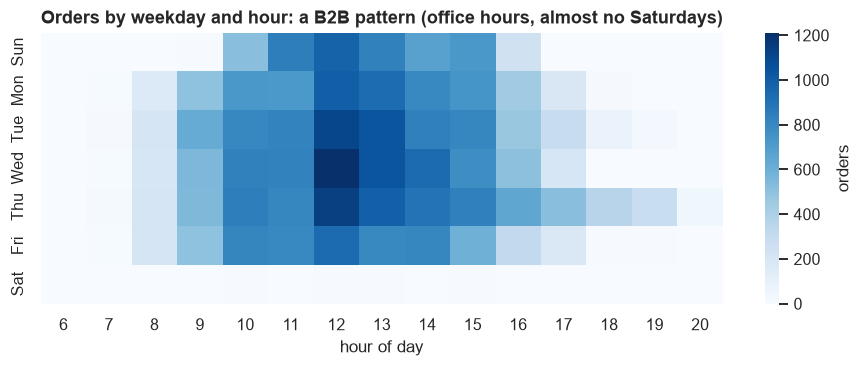

In [11]:
hours = q("""select dayofweek(invoice_ts) dow, hour(invoice_ts) hr, count(distinct invoice_no) orders
             from fct_sales group by 1, 2""")
hm = hours.pivot(index="dow", columns="hr", values="orders").fillna(0)
hm.index = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"][: len(hm)] if len(hm) == 7 else \
    [["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"][i] for i in hm.index]
fig, ax = plt.subplots(figsize=(10, 3.2))
sns.heatmap(hm, cmap="Blues", ax=ax, cbar_kws={"label": "orders"})
ax.set_title("Orders by weekday and hour: a B2B pattern (office hours, almost no Saturdays)")
ax.set_xlabel("hour of day")
ax.set_ylabel("")
save(fig, "eda_weekday_hour")

## 4. Orders and customers

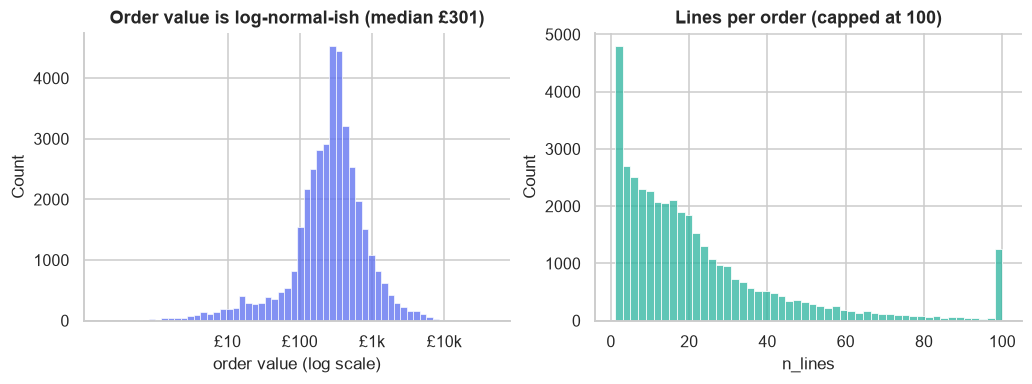

In [12]:
orders = q("select * from fct_orders where not has_outlier")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
sns.histplot(np.log10(orders["order_value"]), bins=60, color=COBALT, ax=axes[0])
axes[0].set_xticks([1, 2, 3, 4], ["£10", "£100", "£1k", "£10k"])
axes[0].set_title("Order value is log-normal-ish (median £%.0f)" % orders["order_value"].median())
axes[0].set_xlabel("order value (log scale)")
sns.histplot(orders["n_lines"].clip(upper=100), bins=50, color=TEAL, ax=axes[1])
axes[1].set_title("Lines per order (capped at 100)")
save(fig, "eda_order_distributions")

In [13]:
guest = orders.groupby("is_guest")["order_value"].agg(["count", "sum", "median"])
guest.index = guest.index.map({False: "identified customer", True: "guest checkout"})
guest

,count,sum,median
is_guest,,,
identified customer,36490,15965889.45,302.200
guest checkout,2916,2367848.88,182.365


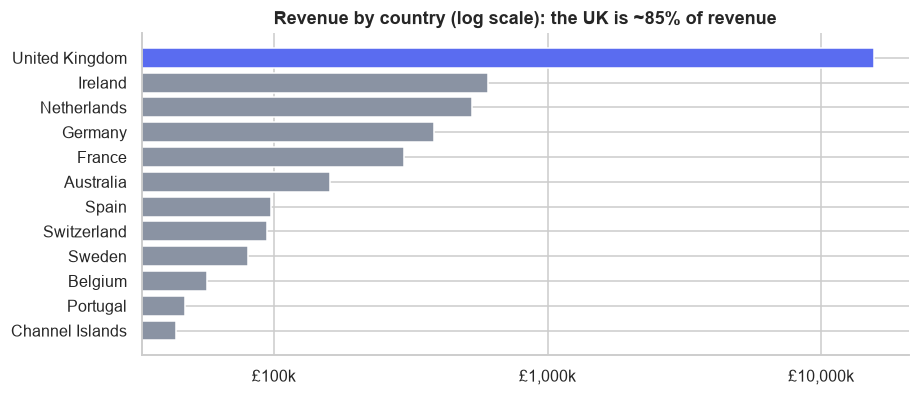

In [14]:
countries = q("select * from mart_country limit 12")
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(countries["country"][::-1], countries["revenue"][::-1], color=[GREY] * 11 + [COBALT])
ax.set_xscale("log")
ax.xaxis.set_major_formatter(gbp)
ax.set_title("Revenue by country (log scale): the UK is ~85% of revenue")
save(fig, "eda_countries")

### How concentrated is customer value?
A Lorenz curve: the share of revenue owned by the top x% of customers.

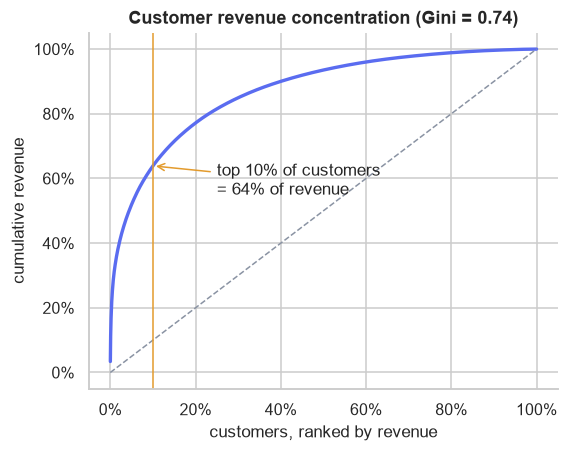

In [15]:
cust = q("select gross_revenue from dim_customer order by gross_revenue desc")["gross_revenue"].clip(lower=0)
share = cust.cumsum() / cust.sum()
pct = np.arange(1, len(cust) + 1) / len(cust)
gini = 1 - 2 * np.trapezoid(np.sort(cust).cumsum() / cust.sum(), dx=1 / len(cust))
top10 = share.iloc[int(len(cust) * 0.1)]

fig, ax = plt.subplots(figsize=(5.5, 4.2))
ax.plot(pct, share, color=COBALT, lw=2.2)
ax.plot([0, 1], [0, 1], color=GREY, ls="--", lw=1)
ax.axvline(0.1, color=AMBER, lw=1)
ax.annotate(f"top 10% of customers\n= {top10:.0%} of revenue", (0.1, top10), (0.25, 0.55),
            arrowprops={"arrowstyle": "->", "color": AMBER})
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title(f"Customer revenue concentration (Gini = {gini:.2f})")
ax.set_xlabel("customers, ranked by revenue")
ax.set_ylabel("cumulative revenue")
save(fig, "eda_lorenz")

### Retention by acquisition cohort

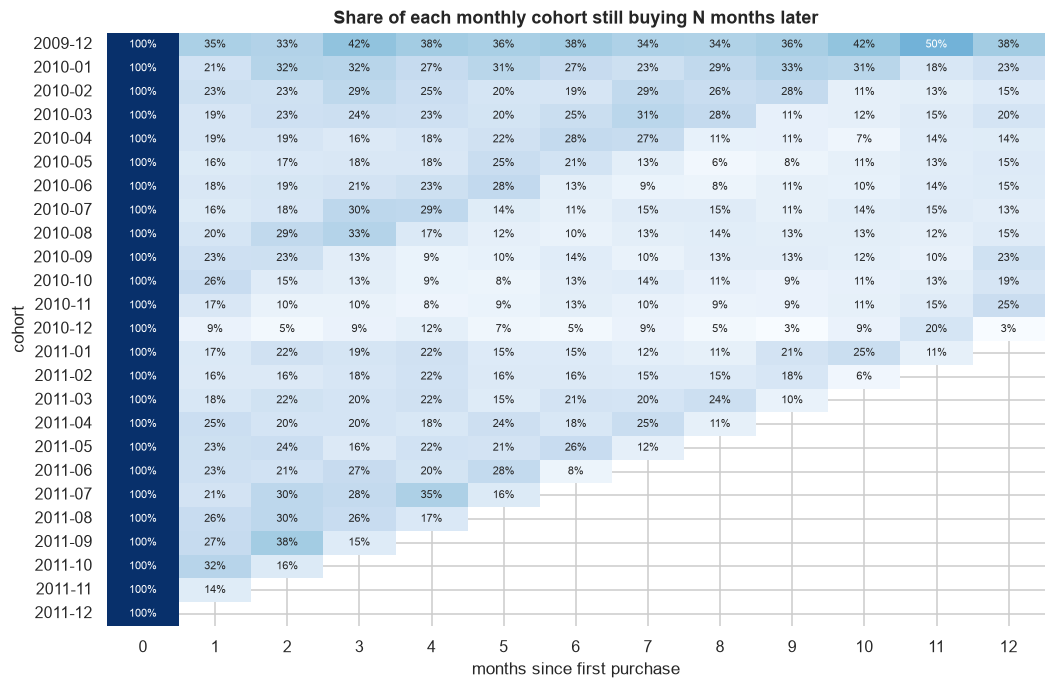

In [16]:
coh = q("select * from mart_cohort_retention where months_since_first <= 12")
grid = coh.pivot(index="cohort", columns="months_since_first", values="retention")
fig, ax = plt.subplots(figsize=(11, 7))
sns.heatmap(grid, annot=True, fmt=".0%", cmap="Blues", ax=ax, cbar=False, annot_kws={"size": 7})
ax.set_title("Share of each monthly cohort still buying N months later")
ax.set_xlabel("months since first purchase")
save(fig, "eda_cohorts")

* The **Dec 2009 cohort is unusually loyal** (~35–50% active each month), but that's an artefact:
  the data starts on 1 Dec 2009, so "first seen in Dec 2009" includes years of existing customers.
  Later cohorts are the true picture: **15–30% month-1 retention**, settling to roughly 10–20%.
* Month 12 often bumps up: customers coming back for the next gift season.

## 5. Products

In [17]:
prod = q("select * from dim_product order by gross_revenue desc")
prod["cum_share"] = prod["gross_revenue"].cumsum() / prod["gross_revenue"].sum()
n80 = (prod["cum_share"] < 0.8).sum() + 1
print(f"{n80:,} of {len(prod):,} products ({n80/len(prod):.0%}) make up 80% of revenue")
prod.head(10)[["product_name", "units_sold", "n_orders", "gross_revenue"]]

1,030 of 4,707 products (22%) make up 80% of revenue


,product_name,units_sold,n_orders,gross_revenue
0,REGENCY CAKESTAND 3 TIER,26478.0,3918,330590.32
1,WHITE HANGING HEART T-LIGHT HOLDER,94719.0,5464,261168.73
2,JUMBO BAG RED RETROSPOT,97176.0,4013,182680.98
3,"PAPER CRAFT , LITTLE BIRDIE",80995.0,1,168469.60
4,PARTY BUNTING,28200.0,2674,148318.28
5,ASSORTED COLOUR BIRD ORNAMENT,80082.0,2807,129324.49
6,PAPER CHAIN KIT 50'S CHRISTMAS,35084.0,2018,117760.29
7,MEDIUM CERAMIC TOP STORAGE JAR,78033.0,247,81700.92
8,CHILLI LIGHTS,15841.0,1135,80540.88
9,SMALL POPCORN HOLDER,88499.0,2322,79520.20


## Summary

| Finding | Consequence for the rest of the project |
|---|---|
| 23% of lines are guest checkouts | Revenue facts keep them; customer models use identified customers only |
| 34k exact duplicate lines, ~18k cancellation lines, fees and postage mixed with products | Rule-based status tagging in the ETL; returns modelled as a separate fact |
| A few huge, cancelled orders (80,995 units) distort totals | Outlier flag (robust z-score per product + absolute cap) |
| Strong Q4 seasonality, closed over Christmas, flat YoY | Forecast needs annual seasonality and a closure effect; YoY growth gets a formal test |
| Heavy concentration (Gini ≈ 0.74): top 10% of customers ≈ 64% of revenue | Lifetime-value modelling and segmentation matter more than average metrics |
| B2B buying rhythm (weekday office hours) | Recency relative to a customer's own cycle is a key churn feature |

In [18]:
con.close()